In [ ]:
API_KEY = 'WxRSAcpuv90pVAdgPMmmQAAely5rpsJ6'

<ipython-input-8-18cdfba76ab8>:90: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1



Portfolio Performance (Jan 2015 - Apr 2025)
CAGR: 18.25%
Annualized Volatility: 14.56%
Sharpe Ratio: 1.12
Maximum Drawdown: 24.34%
Final Portfolio Value: $56,492.56

S&P 500 (SPY) Performance
CAGR: 12.32%
Annualized Volatility: 15.27%
Sharpe Ratio: 0.68
Maximum Drawdown: 23.93%
Final Benchmark Value: $33,192.08


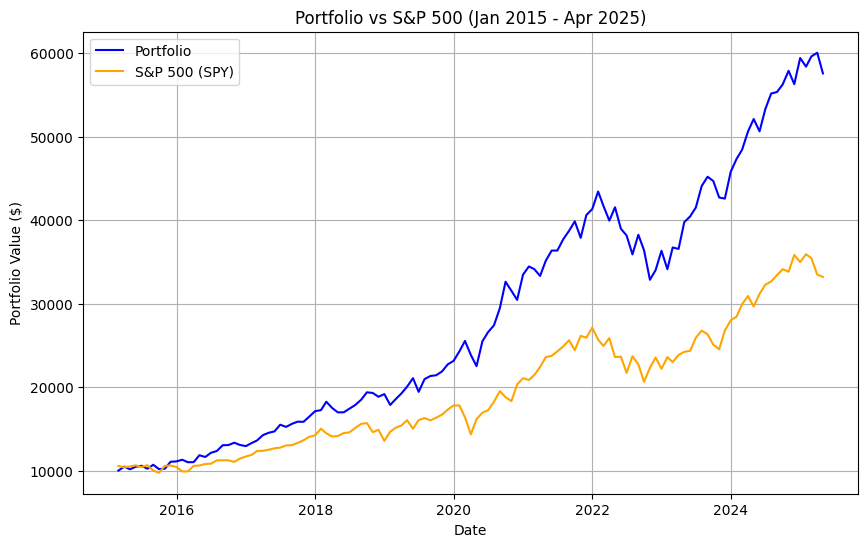

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# FMP API setup
# API_KEY = 'YOUR_API_KEY'  # Replace with your FMP API key
BASE_URL = 'https://financialmodelingprep.com/api/v3'

# Define portfolio stocks
tech_stocks = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META', 'TSLA', 'CSCO', 'INTC', 'QCOM']
safe_haven_stocks = ['PG', 'JNJ', 'KO', 'WMT', 'PEP', 'VZ', 'DUK', 'MRK', 'CL', 'KMB']
all_stocks = tech_stocks + safe_haven_stocks
benchmark = 'SPY'  # S&P 500 ETF

# Define backtest parameters
start_date = '2015-01-01'
end_date = '2025-04-30'
initial_investment = 10000  # $10,000
weights = {stock: 0.05 for stock in all_stocks}  # 5% per stock
risk_free_rate = 0.02  # Annual risk-free rate (e.g., 3-month T-bill)

# Function to fetch historical stock prices from FMP
def get_historical_prices(symbol):
    url = f"{BASE_URL}/historical-price-full/{symbol}?from={start_date}&to={end_date}&apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Error fetching data for {symbol}: {response.status_code}")
        return None
    data = response.json()
    if 'historical' not in data or not data['historical']:
        print(f"No historical data for {symbol}")
        return None
    df = pd.DataFrame(data['historical'])
    df['date'] = pd.to_datetime(df['date'])
    df = df[['date', 'adjClose']].rename(columns={'adjClose': symbol})
    df = df.sort_values('date')  # Ensure chronological order
    return df.set_index('date')

# Download historical data
print("Downloading data from Financial Modeling Prep...")
data_frames = []
for symbol in all_stocks + [benchmark]:
    df = get_historical_prices(symbol)
    if df is not None:
        data_frames.append(df)

# Merge data into a single DataFrame
if not data_frames:
    raise ValueError("No data retrieved from FMP API")
data = pd.concat(data_frames, axis=1, join='inner')

# Check for missing data
if data.isnull().any().any():
    print("Warning: Missing data detected. Filling forward, then backward.")
    data = data.fillna(method='ffill').fillna(method='bfill')

# Calculate monthly returns
monthly_data = data.resample('ME').last()  # End-of-month prices
monthly_returns = monthly_data.pct_change().dropna()

# Portfolio returns with monthly rebalancing
portfolio_value = initial_investment
portfolio_values = [portfolio_value]
portfolio_returns = []

for i in range(len(monthly_returns)):
    # Calculate portfolio return for the month
    month_return = sum(weights[stock] * monthly_returns[stock].iloc[i] for stock in all_stocks)
    portfolio_returns.append(month_return)

    # Update portfolio value
    portfolio_value *= (1 + month_return)
    portfolio_values.append(portfolio_value)

    # Rebalance monthly
    weights = {stock: 0.05 for stock in all_stocks}  # Reset to 5% per stock

# Convert portfolio returns to Series
portfolio_returns = pd.Series(portfolio_returns, index=monthly_returns.index)

# Calculate benchmark returns
benchmark_returns = monthly_returns[benchmark]
benchmark_value = initial_investment * (1 + benchmark_returns).cumprod()

# Performance metrics
def calculate_metrics(returns, portfolio_values, years):
    # CAGR
    cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1

    # Annualized volatility
    annualized_vol = returns.std() * np.sqrt(12)

    # Sharpe Ratio
    excess_return = cagr - risk_free_rate
    sharpe_ratio = excess_return / annualized_vol

    # Maximum Drawdown
    portfolio_values = np.array(portfolio_values)
    rolling_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (rolling_max - portfolio_values) / rolling_max
    max_drawdown = drawdowns.max()

    return cagr, annualized_vol, sharpe_ratio, max_drawdown

# Calculate years for CAGR
start_dt = datetime.strptime(start_date, '%Y-%m-%d')
end_dt = datetime.strptime(end_date, '%Y-%m-%d')
years = (end_dt - start_dt).days / 365.25

# Portfolio metrics
portfolio_cagr, portfolio_vol, portfolio_sharpe, portfolio_mdd = calculate_metrics(
    portfolio_returns, portfolio_values, years
)

# Benchmark metrics
benchmark_cagr, benchmark_vol, benchmark_sharpe, benchmark_mdd = calculate_metrics(
    benchmark_returns, benchmark_value, years
)

# Print results
print("\nPortfolio Performance (Jan 2015 - Apr 2025)")
print(f"CAGR: {portfolio_cagr:.2%}")
print(f"Annualized Volatility: {portfolio_vol:.2%}")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Maximum Drawdown: {portfolio_mdd:.2%}")
print(f"Final Portfolio Value: ${portfolio_values[-1]:,.2f}")

print("\nS&P 500 (SPY) Performance")
print(f"CAGR: {benchmark_cagr:.2%}")
print(f"Annualized Volatility: {benchmark_vol:.2%}")
print(f"Sharpe Ratio: {benchmark_sharpe:.2f}")
print(f"Maximum Drawdown: {benchmark_mdd:.2%}")
print(f"Final Benchmark Value: ${benchmark_value.iloc[-1]:,.2f}")

# Plot portfolio vs benchmark
plt.figure(figsize=(10, 6))
plt.plot(monthly_returns.index, portfolio_values[:-1], label='Portfolio', color='blue')
plt.plot(benchmark_value.index, benchmark_value, label='S&P 500 (SPY)', color='orange')
plt.title('Portfolio vs S&P 500 (Jan 2015 - Apr 2025)')
plt.xlabel('Date')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid()
plt.savefig('portfolio_vs_spy.png')

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# FMP API setup
# API_KEY = 'YOUR_API_KEY'  # Replace with your FMP API key
BASE_URL = 'https://financialmodelingprep.com/api/v3'

# Define portfolio stocks
tech_stocks = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META', 'TSLA', 'CSCO', 'INTC', 'QCOM']
safe_haven_stocks = ['PG', 'JNJ', 'KO', 'WMT', 'PEP', 'VZ', 'DUK', 'MRK', 'CL', 'KMB']
all_stocks = tech_stocks + safe_haven_stocks
benchmark = 'SPY'

# Define backtest parameters
start_date = '2015-01-01'
end_date = '2025-04-30'
initial_investment = 10000
risk_free_rate = 0.02

# Function to fetch historical stock prices from FMP
def get_historical_prices(symbol):
    url = f"{BASE_URL}/historical-price-full/{symbol}?from={start_date}&to={end_date}&apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Error fetching data for {symbol}: {response.status_code}")
        return None
    data = response.json()
    if 'historical' not in data or not data['historical']:
        print(f"No historical data for {symbol}")
        return None
    df = pd.DataFrame(data['historical'])
    df['date'] = pd.to_datetime(df['date'])
    df = df[['date', 'adjClose']].rename(columns={'adjClose': symbol})
    df = df.sort_values('date')  # Ensure chronological order
    return df.set_index('date')

# Function to fetch market cap
def get_market_cap(symbol, date):
    url = f"{BASE_URL}/historical-market-capitalization/{symbol}?from={date}&to={date}&apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code == 200 and response.json():
        data = response.json()
        if data:
            return data[0].get('marketCap', None)
    url = f"{BASE_URL}/company-profile/{symbol}?apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code == 200:
        data = response.json()
        # return data.get('mktCap', None)
        print(data)
    # print(f"Error fetching market cap for {symbol}")
    # return None
get_market_cap('AAPL', '2023-04-30')

# data_frames = []
# for symbol in all_stocks + [benchmark]:
#     df = get_historical_prices(symbol)
#     if df is not None:
#         data_frames.append(df)

# if not data_frames:
#     raise ValueError("No data retrieved from FMP API")
# data = pd.concat(data_frames, axis=1, join='inner')

# if data.isnull().any().any():
#     print("Warning: Missing data detected. Filling forward, then backward.")
#     data = data.fillna(method='ffill').fillna(method='bfill')

# # Calculate monthly returns
# monthly_data = data.resample('ME').last()
# monthly_returns = monthly_data.pct_change().dropna()

# # Calculate market cap weights
# def calculate_market_cap_weights(date):
#     market_caps = {}
#     total_market_cap = 0
#     date_str = date.strftime('%Y-%m-%d')
#     for symbol in all_stocks:
#         market_cap = get_market_cap(symbol, date_str)
#         if market_cap:
#             market_caps[symbol] = market_cap
#             total_market_cap += market_cap
#         else:
#             market_caps[symbol] = 0
#     weights = {symbol: mc / total_market_cap if total_market_cap > 0 else 0 for symbol, mc in market_caps.items()}
#     return weights

# # Portfolio returns with annual rebalancing
# portfolio_value = initial_investment
# portfolio_values = [portfolio_value]
# portfolio_returns = []
# rebalance_dates = monthly_returns.index[::12]
# weights = calculate_market_cap_weights(pd.to_datetime(start_date))
# weight_history = pd.DataFrame(columns=all_stocks, index=monthly_returns.index)

# for i in range(len(monthly_returns)):
#     month_return = sum(weights[stock] * monthly_returns[stock].iloc[i] for stock in all_stocks if weights[stock] > 0)
#     portfolio_returns.append(month_return)
#     portfolio_value *= (1 + month_return)
#     portfolio_values.append(portfolio_value)
#     total_return = 1 + month_return
#     weights = {stock: weights[stock] * (1 + monthly_returns[stock].iloc[i]) / total_return for stock in all_stocks}
#     weight_history.iloc[i] = weights
#     if monthly_returns.index[i] in rebalance_dates:
#         weights = calculate_market_cap_weights(monthly_returns.index[i])
#         print(f"Rebalanced at {monthly_returns.index[i]}: Market cap weights updated")

# portfolio_returns = pd.Series(portfolio_returns, index=monthly_returns.index)

# # Calculate benchmark returns
# benchmark_returns = monthly_returns[benchmark]
# benchmark_value = initial_investment * (1 + benchmark_returns).cumprod()

# # Performance metrics
# def calculate_metrics(returns, portfolio_values, years):
#     portfolio_values = np.array(portfolio_values)
#     cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1
#     annualized_vol = returns.std() * np.sqrt(12)
#     excess_return = cagr - risk_free_rate
#     sharpe_ratio = excess_return / annualized_vol
#     rolling_max = np.maximum.accumulate(portfolio_values)
#     drawdowns = (rolling_max - portfolio_values) / rolling_max
#     max_drawdown = drawdowns.max()
#     return cagr, annualized_vol, sharpe_ratio, max_drawdown

# # Calculate years for CAGR
# start_dt = datetime.strptime(start_date, '%Y-%m-%d')
# end_dt = datetime.strptime(end_date, '%Y-%m-%d')
# years = (end_dt - start_dt).days / 365.25

# # Portfolio and benchmark metrics
# portfolio_cagr, portfolio_vol, portfolio_sharpe, portfolio_mdd = calculate_metrics(
#     portfolio_returns, portfolio_values, years
# )
# benchmark_cagr, benchmark_vol, benchmark_sharpe, benchmark_mdd = calculate_metrics(
#     benchmark_returns, benchmark_value.values, years
# )

# # Print results
# print("\nPortfolio Performance (Jan 2015 - Apr 2025, Annual Rebalancing, Market Cap Weighted)")
# print(f"CAGR: {portfolio_cagr:.2%}")
# print(f"Annualized Volatility: {portfolio_vol:.2%}")
# print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
# print(f"Maximum Drawdown: {portfolio_mdd:.2%}")
# print(f"Final Portfolio Value: ${portfolio_values[-1]:,.2f}")
# print("\nS&P 500 (SPY) Performance")
# print(f"CAGR: {benchmark_cagr:.2%}")
# print(f"Annualized Volatility: {benchmark_vol:.2%}")
# print(f"Sharpe Ratio: {benchmark_sharpe:.2f}")
# print(f"Maximum Drawdown: {benchmark_mdd:.2%}")
# print(f"Final Benchmark Value: ${benchmark_value.iloc[-1]:,.2f}")

# # Plot portfolio vs benchmark
# plt.figure(figsize=(10, 6))
# plt.plot(monthly_returns.index, portfolio_values[:-1], label='Portfolio (Annual, Market Cap)', color='blue')
# plt.plot(benchmark_value.index, benchmark_value, label='S&P 500 (SPY)', color='orange')
# plt.title('Portfolio vs S&P 500 (Jan 2015 - Apr 2025, Annual Rebalancing, Market Cap Weighted)')
# plt.xlabel('Date')
# plt.ylabel('Portfolio Value ($)')
# plt.legend()
# plt.grid()
# plt.savefig('portfolio_vs_spy_annual_market_cap.png')
# plt.close()

# # Plot weight history
# plt.figure(figsize=(12, 6))
# weight_history.plot()
# plt.title('Portfolio Weights Over Time (Annual Rebalancing, Market Cap Weighted)')
# plt.xlabel('Date')
# plt.ylabel('Weight')
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.tight_layout()
# plt.savefig('weights_annual_market_cap.png')
# plt.close()

[]


<ipython-input-10-18cdfba76ab8>:90: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1



Portfolio Performance (Jan 2015 - Apr 2025)
CAGR: 18.25%
Annualized Volatility: 14.56%
Sharpe Ratio: 1.12
Maximum Drawdown: 24.34%
Final Portfolio Value: $56,492.56

S&P 500 (SPY) Performance
CAGR: 12.32%
Annualized Volatility: 15.27%
Sharpe Ratio: 0.68
Maximum Drawdown: 23.93%
Final Benchmark Value: $33,192.08


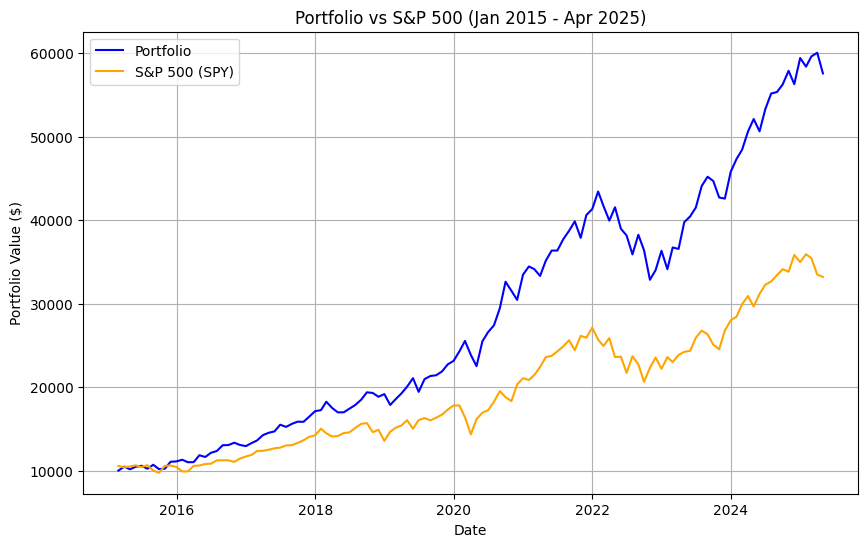

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# FMP API setup
# API_KEY = 'YOUR_API_KEY'  # Replace with your FMP API key
BASE_URL = 'https://financialmodelingprep.com/api/v3'

# Define portfolio stocks
tech_stocks = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META', 'TSLA', 'CSCO', 'INTC', 'QCOM']
safe_haven_stocks = ['PG', 'JNJ', 'KO', 'WMT', 'PEP', 'VZ', 'DUK', 'MRK', 'CL', 'KMB']
all_stocks = tech_stocks + safe_haven_stocks
benchmark = 'SPY'  # S&P 500 ETF

# Define backtest parameters
start_date = '2015-01-01'
end_date = '2025-04-30'
initial_investment = 10000  # $10,000
weights = {stock: 0.05 for stock in all_stocks}  # 5% per stock
risk_free_rate = 0.02  # Annual risk-free rate (e.g., 3-month T-bill)

# Function to fetch historical stock prices from FMP
def get_historical_prices(symbol):
    url = f"{BASE_URL}/historical-price-full/{symbol}?from={start_date}&to={end_date}&apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Error fetching data for {symbol}: {response.status_code}")
        return None
    data = response.json()
    if 'historical' not in data or not data['historical']:
        print(f"No historical data for {symbol}")
        return None
    df = pd.DataFrame(data['historical'])
    df['date'] = pd.to_datetime(df['date'])
    df = df[['date', 'adjClose']].rename(columns={'adjClose': symbol})
    df = df.sort_values('date')  # Ensure chronological order
    return df.set_index('date')

# Download historical data
print("Downloading data from Financial Modeling Prep...")
data_frames = []
for symbol in all_stocks + [benchmark]:
    df = get_historical_prices(symbol)
    if df is not None:
        data_frames.append(df)

# Merge data into a single DataFrame
if not data_frames:
    raise ValueError("No data retrieved from FMP API")
data = pd.concat(data_frames, axis=1, join='inner')

# Check for missing data
if data.isnull().any().any():
    print("Warning: Missing data detected. Filling forward, then backward.")
    data = data.fillna(method='ffill').fillna(method='bfill')

# Calculate monthly returns
monthly_data = data.resample('ME').last()  # End-of-month prices
monthly_returns = monthly_data.pct_change().dropna()

# Portfolio returns with monthly rebalancing
portfolio_value = initial_investment
portfolio_values = [portfolio_value]
portfolio_returns = []

for i in range(len(monthly_returns)):
    # Calculate portfolio return for the month
    month_return = sum(weights[stock] * monthly_returns[stock].iloc[i] for stock in all_stocks)
    portfolio_returns.append(month_return)

    # Update portfolio value
    portfolio_value *= (1 + month_return)
    portfolio_values.append(portfolio_value)

    # Rebalance monthly
    weights = {stock: 0.05 for stock in all_stocks}  # Reset to 5% per stock

# Convert portfolio returns to Series
portfolio_returns = pd.Series(portfolio_returns, index=monthly_returns.index)

# Calculate benchmark returns
benchmark_returns = monthly_returns[benchmark]
benchmark_value = initial_investment * (1 + benchmark_returns).cumprod()

# Performance metrics
def calculate_metrics(returns, portfolio_values, years):
    # CAGR
    cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1

    # Annualized volatility
    annualized_vol = returns.std() * np.sqrt(12)

    # Sharpe Ratio
    excess_return = cagr - risk_free_rate
    sharpe_ratio = excess_return / annualized_vol

    # Maximum Drawdown
    portfolio_values = np.array(portfolio_values)
    rolling_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (rolling_max - portfolio_values) / rolling_max
    max_drawdown = drawdowns.max()

    return cagr, annualized_vol, sharpe_ratio, max_drawdown

# Calculate years for CAGR
start_dt = datetime.strptime(start_date, '%Y-%m-%d')
end_dt = datetime.strptime(end_date, '%Y-%m-%d')
years = (end_dt - start_dt).days / 365.25

# Portfolio metrics
portfolio_cagr, portfolio_vol, portfolio_sharpe, portfolio_mdd = calculate_metrics(
    portfolio_returns, portfolio_values, years
)

# Benchmark metrics
benchmark_cagr, benchmark_vol, benchmark_sharpe, benchmark_mdd = calculate_metrics(
    benchmark_returns, benchmark_value, years
)

# Print results
print("\nPortfolio Performance (Jan 2015 - Apr 2025)")
print(f"CAGR: {portfolio_cagr:.2%}")
print(f"Annualized Volatility: {portfolio_vol:.2%}")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Maximum Drawdown: {portfolio_mdd:.2%}")
print(f"Final Portfolio Value: ${portfolio_values[-1]:,.2f}")

print("\nS&P 500 (SPY) Performance")
print(f"CAGR: {benchmark_cagr:.2%}")
print(f"Annualized Volatility: {benchmark_vol:.2%}")
print(f"Sharpe Ratio: {benchmark_sharpe:.2f}")
print(f"Maximum Drawdown: {benchmark_mdd:.2%}")
print(f"Final Benchmark Value: ${benchmark_value.iloc[-1]:,.2f}")

# Plot portfolio vs benchmark
plt.figure(figsize=(10, 6))
plt.plot(monthly_returns.index, portfolio_values[:-1], label='Portfolio', color='blue')
plt.plot(benchmark_value.index, benchmark_value, label='S&P 500 (SPY)', color='orange')
plt.title('Portfolio vs S&P 500 (Jan 2015 - Apr 2025)')
plt.xlabel('Date')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid()
plt.savefig('portfolio_vs_spy.png')

<ipython-input-11-7423313bc071>:90: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1



Portfolio Performance (Jan 2015 - Apr 2025)
CAGR: 14.01%
Annualized Volatility: 11.60%
Sharpe Ratio: 1.04
Maximum Drawdown: 22.88%
Final Portfolio Value: $38,723.26

S&P 500 (SPY) Performance
CAGR: 12.32%
Annualized Volatility: 15.27%
Sharpe Ratio: 0.68
Maximum Drawdown: 23.93%
Final Benchmark Value: $33,192.08


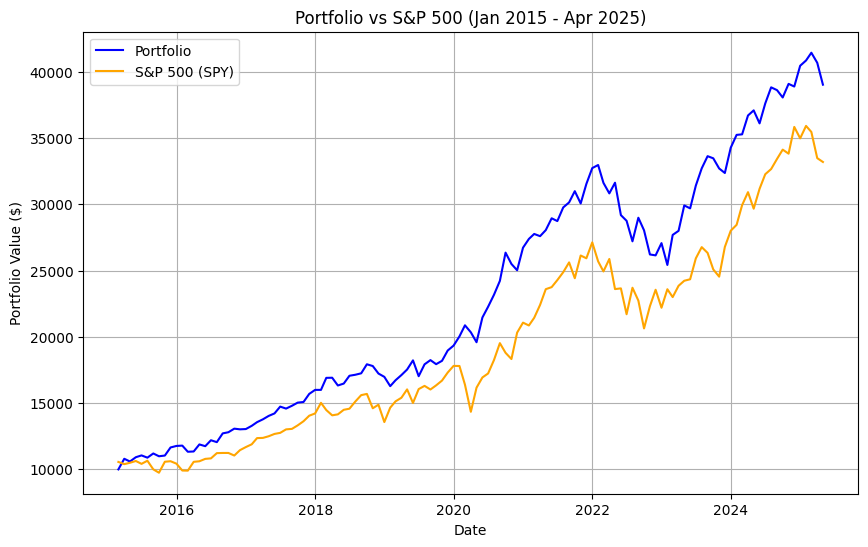

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# FMP API setup
# API_KEY = 'YOUR_API_KEY'  # Replace with your FMP API key
BASE_URL = 'https://financialmodelingprep.com/api/v3'

# Define portfolio stocks
tech_stocks = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META', 'TSLA', 'CSCO', 'INTC', 'QCOM']
safe_haven_stocks = []
all_stocks = tech_stocks + safe_haven_stocks
benchmark = 'SPY'  # S&P 500 ETF

# Define backtest parameters
start_date = '2015-01-01'
end_date = '2025-04-30'
initial_investment = 10000  # $10,000
weights = {stock: 0.1 for stock in all_stocks}  # 5% per stock
risk_free_rate = 0.02  # Annual risk-free rate (e.g., 3-month T-bill)

# Function to fetch historical stock prices from FMP
def get_historical_prices(symbol):
    url = f"{BASE_URL}/historical-price-full/{symbol}?from={start_date}&to={end_date}&apikey={API_KEY}"
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Error fetching data for {symbol}: {response.status_code}")
        return None
    data = response.json()
    if 'historical' not in data or not data['historical']:
        print(f"No historical data for {symbol}")
        return None
    df = pd.DataFrame(data['historical'])
    df['date'] = pd.to_datetime(df['date'])
    df = df[['date', 'adjClose']].rename(columns={'adjClose': symbol})
    df = df.sort_values('date')  # Ensure chronological order
    return df.set_index('date')

# Download historical data
print("Downloading data from Financial Modeling Prep...")
data_frames = []
for symbol in all_stocks + [benchmark]:
    df = get_historical_prices(symbol)
    if df is not None:
        data_frames.append(df)

# Merge data into a single DataFrame
if not data_frames:
    raise ValueError("No data retrieved from FMP API")
data = pd.concat(data_frames, axis=1, join='inner')

# Check for missing data
if data.isnull().any().any():
    print("Warning: Missing data detected. Filling forward, then backward.")
    data = data.fillna(method='ffill').fillna(method='bfill')

# Calculate monthly returns
monthly_data = data.resample('ME').last()  # End-of-month prices
monthly_returns = monthly_data.pct_change().dropna()

# Portfolio returns with monthly rebalancing
portfolio_value = initial_investment
portfolio_values = [portfolio_value]
portfolio_returns = []

for i in range(len(monthly_returns)):
    # Calculate portfolio return for the month
    month_return = sum(weights[stock] * monthly_returns[stock].iloc[i] for stock in all_stocks)
    portfolio_returns.append(month_return)

    # Update portfolio value
    portfolio_value *= (1 + month_return)
    portfolio_values.append(portfolio_value)

    # Rebalance monthly
    weights = {stock: 0.05 for stock in all_stocks}  # Reset to 5% per stock

# Convert portfolio returns to Series
portfolio_returns = pd.Series(portfolio_returns, index=monthly_returns.index)

# Calculate benchmark returns
benchmark_returns = monthly_returns[benchmark]
benchmark_value = initial_investment * (1 + benchmark_returns).cumprod()

# Performance metrics
def calculate_metrics(returns, portfolio_values, years):
    # CAGR
    cagr = (portfolio_values[-1] / initial_investment) ** (1 / years) - 1

    # Annualized volatility
    annualized_vol = returns.std() * np.sqrt(12)

    # Sharpe Ratio
    excess_return = cagr - risk_free_rate
    sharpe_ratio = excess_return / annualized_vol

    # Maximum Drawdown
    portfolio_values = np.array(portfolio_values)
    rolling_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (rolling_max - portfolio_values) / rolling_max
    max_drawdown = drawdowns.max()

    return cagr, annualized_vol, sharpe_ratio, max_drawdown

# Calculate years for CAGR
start_dt = datetime.strptime(start_date, '%Y-%m-%d')
end_dt = datetime.strptime(end_date, '%Y-%m-%d')
years = (end_dt - start_dt).days / 365.25

# Portfolio metrics
portfolio_cagr, portfolio_vol, portfolio_sharpe, portfolio_mdd = calculate_metrics(
    portfolio_returns, portfolio_values, years
)

# Benchmark metrics
benchmark_cagr, benchmark_vol, benchmark_sharpe, benchmark_mdd = calculate_metrics(
    benchmark_returns, benchmark_value, years
)

# Print results
print("\nPortfolio Performance (Jan 2015 - Apr 2025)")
print(f"CAGR: {portfolio_cagr:.2%}")
print(f"Annualized Volatility: {portfolio_vol:.2%}")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Maximum Drawdown: {portfolio_mdd:.2%}")
print(f"Final Portfolio Value: ${portfolio_values[-1]:,.2f}")

print("\nS&P 500 (SPY) Performance")
print(f"CAGR: {benchmark_cagr:.2%}")
print(f"Annualized Volatility: {benchmark_vol:.2%}")
print(f"Sharpe Ratio: {benchmark_sharpe:.2f}")
print(f"Maximum Drawdown: {benchmark_mdd:.2%}")
print(f"Final Benchmark Value: ${benchmark_value.iloc[-1]:,.2f}")

# Plot portfolio vs benchmark
plt.figure(figsize=(10, 6))
plt.plot(monthly_returns.index, portfolio_values[:-1], label='Portfolio', color='blue')
plt.plot(benchmark_value.index, benchmark_value, label='S&P 500 (SPY)', color='orange')
plt.title('Portfolio vs S&P 500 (Jan 2015 - Apr 2025)')
plt.xlabel('Date')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid()
plt.savefig('portfolio_vs_spy.png')

<ipython-input-20-8466892bb212>:96: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
<ipython-input-20-8466892bb212>:104: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100


Start Date: 2015-05-22

Portfolio Metrics:
Annualized Return: 31.59%
Sharpe Ratio: 1.08
Max Drawdown: -46.59%

S&P 500 (SPY) Metrics:
Annualized Return: 12.76%
Sharpe Ratio: 0.64
Max Drawdown: -33.72%


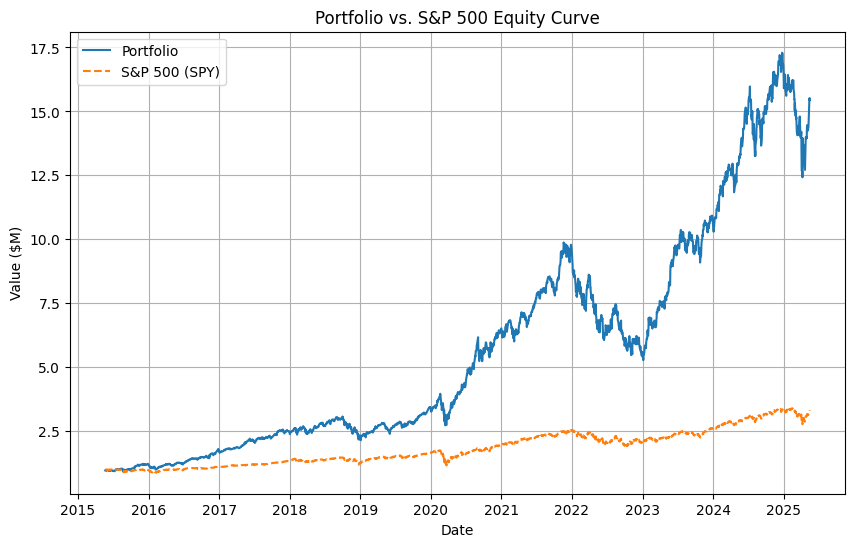

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define stocks and benchmark
safe_haven = ['PG', 'JNJ', 'KO', 'PEP', 'WMT', 'CL', 'KMB', 'MCD', 'DUK', 'SO']
tech = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'ADBE', 'CRM', 'INTC']
tickers = safe_haven + tech + ['SPY']  # Add SPY for S&P 500

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = end_date - timedelta(days=365*10)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure SPY is included
if 'SPY' not in tickers:
    raise ValueError("SPY data unavailable for the specified period.")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Fetch market cap (latest available) for portfolio stocks only
market_caps = {}
for ticker in tickers:
    if ticker != 'SPY':  # Exclude SPY
        stock = yf.Ticker(ticker)
        info = stock.info
        market_caps[ticker] = info.get('marketCap', np.nan)

market_cap_df = pd.Series(market_caps)

# Initialize portfolio
initial_investment = 1000000  # $1M
portfolio_value = []
weights_df = pd.DataFrame(index=data.index, columns=tickers[:-1])  # Exclude SPY
returns = data.pct_change().dropna()

# Rebalance annually
current_date = start_date
portfolio_holdings = initial_investment
shares = pd.Series(0.0, index=tickers[:-1])  # Exclude SPY

while current_date <= data.index[-1]:
    # Get market caps at rebalance
    total_market_cap = market_cap_df.sum()
    weights = market_cap_df / total_market_cap

    # Store weights
    weights_df.loc[current_date] = weights

    # Calculate shares to buy
    prices = data.loc[current_date][tickers[:-1]]  # Exclude SPY
    allocation = portfolio_holdings * weights
    shares = allocation / prices

    # Find next rebalance date (end of year)
    next_rebalance = current_date + pd.offsets.YearEnd()
    if next_rebalance > data.index[-1]:
        next_rebalance = data.index[-1]

    # Calculate portfolio value until next rebalance
    date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
    for date in date_range:
        portfolio_value.append((shares * data.loc[date][tickers[:-1]]).sum())
        weights_df.loc[date] = weights_df.loc[current_date]

    # Update portfolio holdings
    portfolio_holdings = portfolio_value[-1]

    # Move to next trading day after rebalance
    current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

# Create portfolio value DataFrame
portfolio_value = pd.Series(portfolio_value, index=data.index[:len(portfolio_value)])

# Calculate SPY performance
spy_value = initial_investment * (data['SPY'] / data['SPY'][start_date])

# Calculate metrics for portfolio
daily_returns = portfolio_value.pct_change().dropna()
years = (portfolio_value.index[-1] - portfolio_value.index[0]).days / 365.25
portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
portfolio_sharpe = (daily_returns.mean() * 252 - 0.02) / (daily_returns.std() * np.sqrt(252))
rolling_max = portfolio_value.cummax()
drawdown = (portfolio_value - rolling_max) / rolling_max
portfolio_max_drawdown = drawdown.min() * 100

# Calculate metrics for SPY
spy_daily_returns = spy_value.pct_change().dropna()
spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100
spy_sharpe = (spy_daily_returns.mean() * 252 - 0.02) / (spy_daily_returns.std() * np.sqrt(252))
spy_rolling_max = spy_value.cummax()
spy_drawdown = (spy_value - spy_rolling_max) / spy_rolling_max
spy_max_drawdown = spy_drawdown.min() * 100

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
print("\nPortfolio Metrics:")
print(f"Annualized Return: {portfolio_annualized_return:.2f}%")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Max Drawdown: {portfolio_max_drawdown:.2f}%")
print("\nS&P 500 (SPY) Metrics:")
print(f"Annualized Return: {spy_annualized_return:.2f}%")
print(f"Sharpe Ratio: {spy_sharpe:.2f}")
print(f"Max Drawdown: {spy_max_drawdown:.2f}%")

# Plot equity curves
plt.figure(figsize=(10, 6))
plt.plot(portfolio_value.index, portfolio_value / initial_investment, label='Portfolio')
plt.plot(spy_value.index, spy_value / initial_investment, label='S&P 500 (SPY)', linestyle='--')
plt.title('Portfolio vs. S&P 500 Equity Curve')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
plt.savefig('equity_curve_comparison.png')
# plt.close()

# # Save results to file
# results = {
#     'Start Date': start_date.strftime('%Y-%m-%d'),
#     'Portfolio Annualized Return (%)': portfolio_annualized_return,
#     'Portfolio Sharpe Ratio': portfolio_sharpe,
#     'Portfolio Max Drawdown (%)': portfolio_max_drawdown,
#     'SPY Annualized Return (%)': spy_annualized_return,
#     'SPY Sharpe Ratio': spy_sharpe,
#     'SPY Max Drawdown (%)': spy_max_drawdown
# }
# pd.Series(results).to_csv('backtest_results.csv')

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FB']: YFTzMissingError('possibly delisted; no timezone found')


<ipython-input-22-f2c2ff415b1f>:96: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
<ipython-input-22-f2c2ff415b1f>:104: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100


Start Date: 2015-05-22

Portfolio Metrics:
Annualized Return: 15.32%
Sharpe Ratio: 0.67
Max Drawdown: -37.63%

S&P 500 (SPY) Metrics:
Annualized Return: 12.76%
Sharpe Ratio: 0.64
Max Drawdown: -33.72%


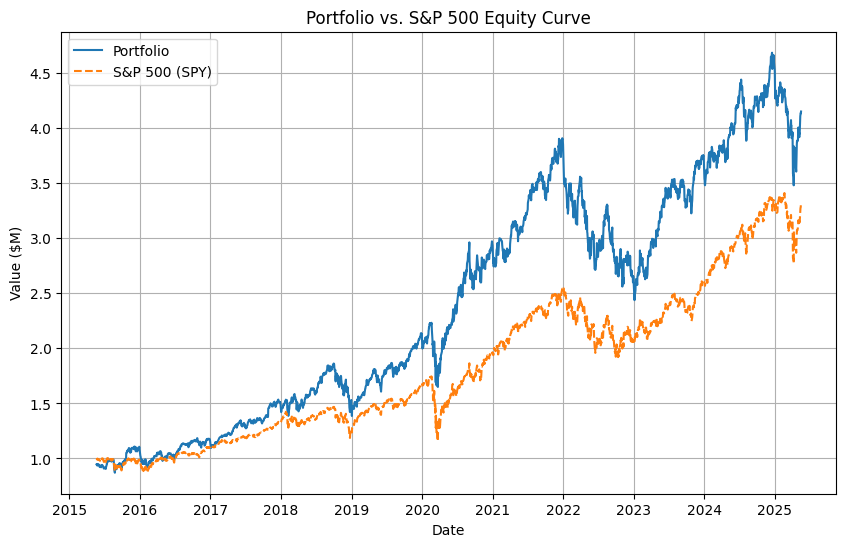

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define stocks and benchmark
tech = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'FB', 'CSCO', 'INTC', 'IBM', 'ORCL', 'QCOM']
safe_haven = ['WMT', 'PG', 'KO', 'PEP', 'CVS', 'JNJ', 'PFE', 'MRK', 'DUK', 'SO']
tickers = safe_haven + tech + ['SPY']  # Add SPY for S&P 500

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = end_date - timedelta(days=365*10)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure SPY is included
if 'SPY' not in tickers:
    raise ValueError("SPY data unavailable for the specified period.")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Fetch market cap (latest available) for portfolio stocks only
market_caps = {}
for ticker in tickers:
    if ticker != 'SPY':  # Exclude SPY
        stock = yf.Ticker(ticker)
        info = stock.info
        market_caps[ticker] = info.get('marketCap', np.nan)

market_cap_df = pd.Series(market_caps)

# Initialize portfolio
initial_investment = 1000000  # $1M
portfolio_value = []
weights_df = pd.DataFrame(index=data.index, columns=tickers[:-1])  # Exclude SPY
returns = data.pct_change().dropna()

# Rebalance annually
current_date = start_date
portfolio_holdings = initial_investment
shares = pd.Series(0.0, index=tickers[:-1])  # Exclude SPY

while current_date <= data.index[-1]:
    # Get market caps at rebalance
    total_market_cap = market_cap_df.sum()
    weights = market_cap_df / total_market_cap

    # Store weights
    weights_df.loc[current_date] = weights

    # Calculate shares to buy
    prices = data.loc[current_date][tickers[:-1]]  # Exclude SPY
    allocation = portfolio_holdings * weights
    shares = allocation / prices

    # Find next rebalance date (end of year)
    next_rebalance = current_date + pd.offsets.YearEnd()
    if next_rebalance > data.index[-1]:
        next_rebalance = data.index[-1]

    # Calculate portfolio value until next rebalance
    date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
    for date in date_range:
        portfolio_value.append((shares * data.loc[date][tickers[:-1]]).sum())
        weights_df.loc[date] = weights_df.loc[current_date]

    # Update portfolio holdings
    portfolio_holdings = portfolio_value[-1]

    # Move to next trading day after rebalance
    current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

# Create portfolio value DataFrame
portfolio_value = pd.Series(portfolio_value, index=data.index[:len(portfolio_value)])

# Calculate SPY performance
spy_value = initial_investment * (data['SPY'] / data['SPY'][start_date])

# Calculate metrics for portfolio
daily_returns = portfolio_value.pct_change().dropna()
years = (portfolio_value.index[-1] - portfolio_value.index[0]).days / 365.25
portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
portfolio_sharpe = (daily_returns.mean() * 252 - 0.02) / (daily_returns.std() * np.sqrt(252))
rolling_max = portfolio_value.cummax()
drawdown = (portfolio_value - rolling_max) / rolling_max
portfolio_max_drawdown = drawdown.min() * 100

# Calculate metrics for SPY
spy_daily_returns = spy_value.pct_change().dropna()
spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100
spy_sharpe = (spy_daily_returns.mean() * 252 - 0.02) / (spy_daily_returns.std() * np.sqrt(252))
spy_rolling_max = spy_value.cummax()
spy_drawdown = (spy_value - spy_rolling_max) / spy_rolling_max
spy_max_drawdown = spy_drawdown.min() * 100

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
print("\nPortfolio Metrics:")
print(f"Annualized Return: {portfolio_annualized_return:.2f}%")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Max Drawdown: {portfolio_max_drawdown:.2f}%")
print("\nS&P 500 (SPY) Metrics:")
print(f"Annualized Return: {spy_annualized_return:.2f}%")
print(f"Sharpe Ratio: {spy_sharpe:.2f}")
print(f"Max Drawdown: {spy_max_drawdown:.2f}%")

# Plot equity curves
plt.figure(figsize=(10, 6))
plt.plot(portfolio_value.index, portfolio_value / initial_investment, label='Portfolio')
plt.plot(spy_value.index, spy_value / initial_investment, label='S&P 500 (SPY)', linestyle='--')
plt.title('Portfolio vs. S&P 500 Equity Curve')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
plt.savefig('equity_curve_comparison.png')
# plt.close()

# # Save results to file
# results = {
#     'Start Date': start_date.strftime('%Y-%m-%d'),
#     'Portfolio Annualized Return (%)': portfolio_annualized_return,
#     'Portfolio Sharpe Ratio': portfolio_sharpe,
#     'Portfolio Max Drawdown (%)': portfolio_max_drawdown,
#     'SPY Annualized Return (%)': spy_annualized_return,
#     'SPY Sharpe Ratio': spy_sharpe,
#     'SPY Max Drawdown (%)': spy_max_drawdown
# }
# pd.Series(results).to_csv('backtest_results.csv')

<ipython-input-27-0b46da325d73>:96: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
<ipython-input-27-0b46da325d73>:104: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100


Start Date: 2015-01-02

Portfolio Metrics:
Annualized Return: 14.65%
Sharpe Ratio: 0.75
Max Drawdown: -29.43%

S&P 500 (SPY) Metrics:
Annualized Return: 12.70%
Sharpe Ratio: 0.64
Max Drawdown: -33.72%


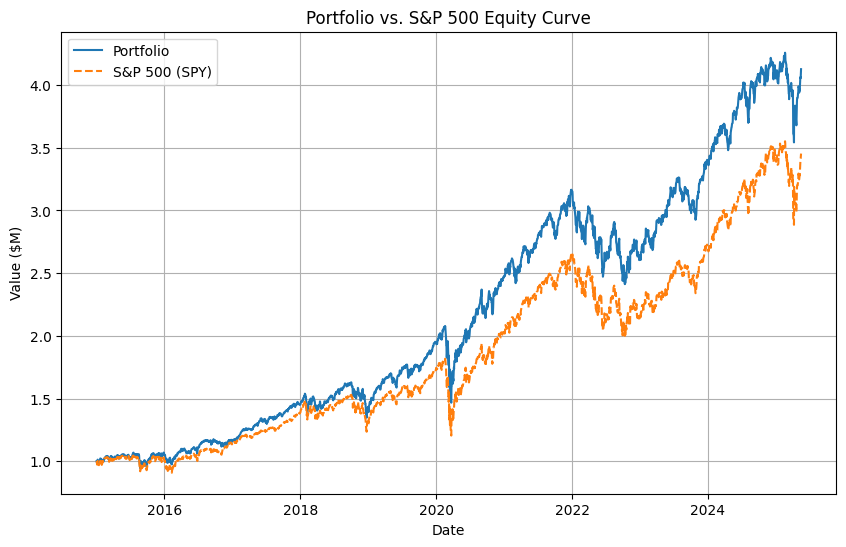

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define ETFs
tech_etfs = ['QQQ', 'XLK', 'VGT', 'IYW', 'IXN']
safe_haven_etfs = ['XLP', 'XLV', 'XLU', 'VDC', 'VHT']
# safe_haven_etfs = []
all_etfs = tech_etfs + safe_haven_etfs
tickers = all_etfs + ['SPY']  # Add SPY for S&P 500

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = datetime(2015, 1, 1)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure SPY is included
if 'SPY' not in tickers:
    raise ValueError("SPY data unavailable for the specified period.")

# Ensure all ETFs are available
if not all(t in tickers for t in all_etfs):
    missing = [t for t in all_etfs if t not in tickers]
    raise ValueError(f"Missing data for ETFs: {missing}")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Initialize portfolio
initial_investment = 1000000  # $1M
portfolio_value = []
weights_df = pd.DataFrame(index=data.index, columns=all_etfs)
returns = data.pct_change().dropna()

# Equal weights
n_etfs = len(all_etfs)
weight = 1.0 / n_etfs  # 10% per ETF

# Rebalance annually
current_date = start_date
portfolio_holdings = initial_investment
shares = pd.Series(0.0, index=all_etfs)

while current_date <= data.index[-1]:
    # Set equal weights
    weights = pd.Series(weight, index=all_etfs)

    # Store weights
    weights_df.loc[current_date] = weights

    # Calculate shares to buy
    prices = data.loc[current_date][all_etfs]
    allocation = portfolio_holdings * weights
    shares = allocation / prices

    # Find next rebalance date (end of year)
    next_rebalance = current_date + pd.offsets.YearEnd()
    if next_rebalance > data.index[-1]:
        next_rebalance = data.index[-1]

    # Calculate portfolio value until next rebalance
    date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
    for date in date_range:
        portfolio_value.append((shares * data.loc[date][all_etfs]).sum())
        weights_df.loc[date] = weights_df.loc[current_date]

    # Update portfolio holdings
    portfolio_holdings = portfolio_value[-1]

    # Move to next trading day after rebalance
    current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

# Create portfolio value DataFrame
portfolio_value = pd.Series(portfolio_value, index=data.index[:len(portfolio_value)])

# Calculate SPY performance
spy_value = initial_investment * (data['SPY'] / data['SPY'][start_date])

# Calculate metrics for portfolio
daily_returns = portfolio_value.pct_change().dropna()
years = (portfolio_value.index[-1] - portfolio_value.index[0]).days / 365.25
portfolio_annualized_return = ((portfolio_value[-1] / initial_investment) ** (1/years) - 1) * 100
portfolio_sharpe = (daily_returns.mean() * 252 - 0.02) / (daily_returns.std() * np.sqrt(252))
rolling_max = portfolio_value.cummax()
drawdown = (portfolio_value - rolling_max) / rolling_max
portfolio_max_drawdown = drawdown.min() * 100

# Calculate metrics for SPY
spy_daily_returns = spy_value.pct_change().dropna()
spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100
spy_sharpe = (spy_daily_returns.mean() * 252 - 0.02) / (spy_daily_returns.std() * np.sqrt(252))
spy_rolling_max = spy_value.cummax()
spy_drawdown = (spy_value - spy_rolling_max) / spy_rolling_max
spy_max_drawdown = spy_drawdown.min() * 100

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
print("\nPortfolio Metrics:")
print(f"Annualized Return: {portfolio_annualized_return:.2f}%")
print(f"Sharpe Ratio: {portfolio_sharpe:.2f}")
print(f"Max Drawdown: {portfolio_max_drawdown:.2f}%")
print("\nS&P 500 (SPY) Metrics:")
print(f"Annualized Return: {spy_annualized_return:.2f}%")
print(f"Sharpe Ratio: {spy_sharpe:.2f}")
print(f"Max Drawdown: {spy_max_drawdown:.2f}%")

# Plot equity curves
plt.figure(figsize=(10, 6))
plt.plot(portfolio_value.index, portfolio_value / initial_investment, label='Portfolio')
plt.plot(spy_value.index, spy_value / initial_investment, label='S&P 500 (SPY)', linestyle='--')
plt.title('Portfolio vs. S&P 500 Equity Curve')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
plt.savefig('equity_curve_comparison.png')
# plt.close()

# Save results to file
results = {
    'Start Date': start_date.strftime('%Y-%m-%d'),
    'Portfolio Annualized Return (%)': portfolio_annualized_return,
    'Portfolio Sharpe Ratio': portfolio_sharpe,
    'Portfolio Max Drawdown (%)': portfolio_max_drawdown,
    'SPY Annualized Return (%)': spy_annualized_return,
    'SPY Sharpe Ratio': spy_sharpe,
    'SPY Max Drawdown (%)': spy_max_drawdown
}
pd.Series(results).to_csv('backtest_results.csv')

<ipython-input-29-d58a221d6d83>:104: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  annualized_return = ((portfolio_values[sector][-1] / initial_investment) ** (1/years) - 1) * 100
<ipython-input-29-d58a221d6d83>:117: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100


Start Date: 2015-10-08

Technology Metrics:
Annualized Return: 20.91%
Sharpe Ratio: 0.83
Max Drawdown: -36.27%

Safe-Haven Metrics:
Annualized Return: 9.41%
Sharpe Ratio: 0.55
Max Drawdown: -28.47%

Pharmacy Metrics:
Annualized Return: 2.32%
Sharpe Ratio: 0.11
Max Drawdown: -33.12%

Real Estate Metrics:
Annualized Return: 6.59%
Sharpe Ratio: 0.32
Max Drawdown: -41.92%

Financials Metrics:
Annualized Return: 11.59%
Sharpe Ratio: 0.50
Max Drawdown: -44.71%

Energy Metrics:
Annualized Return: 5.01%
Sharpe Ratio: 0.25
Max Drawdown: -69.16%

Consumer Discretionary Metrics:
Annualized Return: 12.80%
Sharpe Ratio: 0.57
Max Drawdown: -39.71%

S&P 500 (SPY) Metrics:
Annualized Return: 13.85%
Sharpe Ratio: 0.69
Max Drawdown: -33.72%


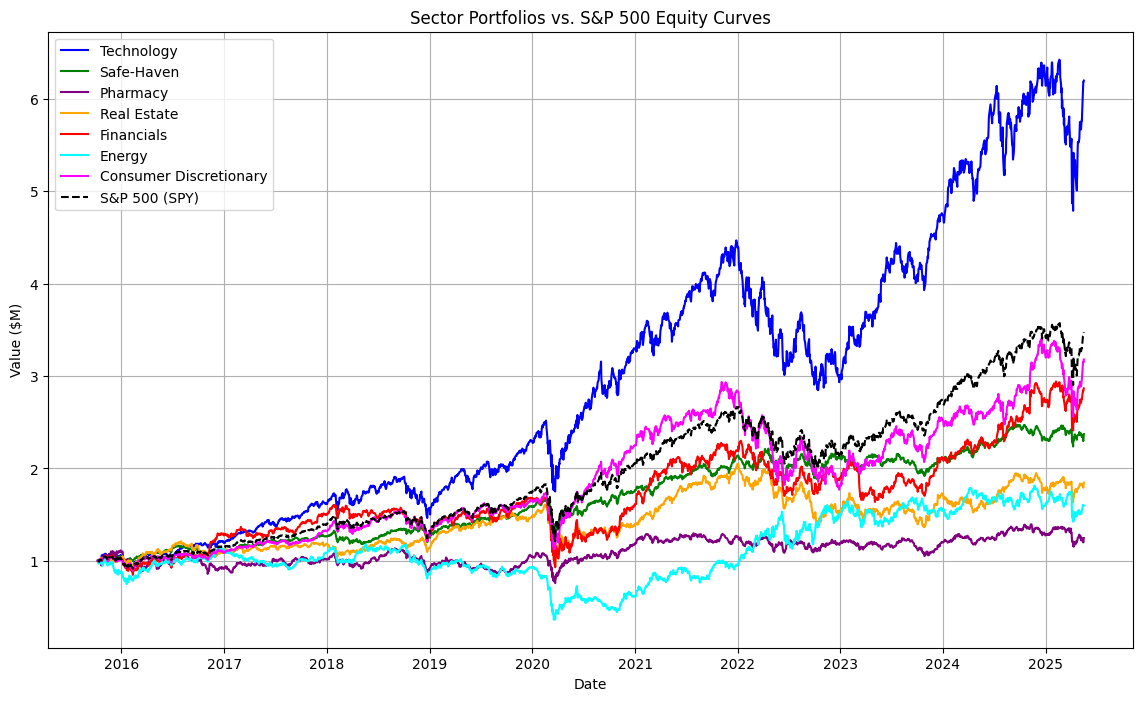

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define ETFs by sector
sectors = {
    'Technology': ['QQQ', 'XLK', 'VGT', 'IYW', 'IXN'],
    'Safe-Haven': ['XLP', 'XLV', 'XLU', 'VDC', 'VHT'],
    'Pharmacy': ['IHE', 'XPH', 'PJP'],
    'Real Estate': ['VNQ', 'XLRE', 'IYR', 'SCHH'],
    'Financials': ['XLF', 'VFH', 'IYF', 'KBE'],
    'Energy': ['XLE', 'VDE', 'IYE'],
    'Consumer Discretionary': ['XLY', 'VCR', 'IYC', 'FDIS']
}
tickers = [etf for sector in sectors.values() for etf in sector] + ['SPY']
tickers = list(dict.fromkeys(tickers))  # Remove duplicates

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = datetime(2015, 1, 1)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure SPY is included
if 'SPY' not in tickers:
    raise ValueError("SPY data unavailable for the specified period.")

# Update sectors to exclude dropped tickers
for sector, etfs in sectors.items():
    sectors[sector] = [etf for etf in etfs if etf in tickers]
    if not sectors[sector]:
        raise ValueError(f"No available ETFs for {sector} sector.")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Initialize portfolios
initial_investment = 1000000  # $1M
portfolio_values = {sector: [] for sector in sectors}
weights_dfs = {sector: pd.DataFrame(index=data.index, columns=etfs) for sector, etfs in sectors.items()}

# Backtest each sector portfolio
for sector, etfs in sectors.items():
    n_etfs = len(etfs)
    weight = 1.0 / n_etfs  # Equal weight
    current_date = start_date
    holdings = initial_investment
    shares = pd.Series(0.0, index=etfs)

    while current_date <= data.index[-1]:
        # Set equal weights
        weights = pd.Series(weight, index=etfs)

        # Store weights
        weights_dfs[sector].loc[current_date] = weights

        # Calculate shares to buy
        prices = data.loc[current_date][etfs]
        allocation = holdings * weights
        shares = allocation / prices

        # Find next rebalance date (end of year)
        next_rebalance = current_date + pd.offsets.YearEnd()
        if next_rebalance > data.index[-1]:
            next_rebalance = data.index[-1]

        # Calculate portfolio value until next rebalance
        date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
        for date in date_range:
            portfolio_values[sector].append((shares * data.loc[date][etfs]).sum())
            weights_dfs[sector].loc[date] = weights_dfs[sector].loc[current_date]

        # Update portfolio holdings
        holdings = portfolio_values[sector][-1]

        # Move to next trading day after rebalance
        current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

    # Create portfolio value Series
    portfolio_values[sector] = pd.Series(portfolio_values[sector], index=data.index[:len(portfolio_values[sector])])

# Calculate SPY performance
spy_value = initial_investment * (data['SPY'] / data['SPY'][start_date])

# Calculate metrics for each sector portfolio
metrics = {}
years = (spy_value.index[-1] - spy_value.index[0]).days / 365.25

for sector in sectors:
    daily_returns = portfolio_values[sector].pct_change().dropna()
    annualized_return = ((portfolio_values[sector][-1] / initial_investment) ** (1/years) - 1) * 100
    sharpe = (daily_returns.mean() * 252 - 0.02) / (daily_returns.std() * np.sqrt(252))
    rolling_max = portfolio_values[sector].cummax()
    drawdown = (portfolio_values[sector] - rolling_max) / rolling_max
    max_drawdown = drawdown.min() * 100
    metrics[sector] = {
        'Annualized Return (%)': annualized_return,
        'Sharpe Ratio': sharpe,
        'Max Drawdown (%)': max_drawdown
    }

# Calculate metrics for SPY
spy_daily_returns = spy_value.pct_change().dropna()
spy_annualized_return = ((spy_value[-1] / initial_investment) ** (1/years) - 1) * 100
spy_sharpe = (spy_daily_returns.mean() * 252 - 0.02) / (spy_daily_returns.std() * np.sqrt(252))
spy_rolling_max = spy_value.cummax()
spy_drawdown = (spy_value - spy_rolling_max) / spy_rolling_max
spy_max_drawdown = spy_drawdown.min() * 100
metrics['S&P 500 (SPY)'] = {
    'Annualized Return (%)': spy_annualized_return,
    'Sharpe Ratio': spy_sharpe,
    'Max Drawdown (%)': spy_max_drawdown
}

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
for sector, metric in metrics.items():
    print(f"\n{sector} Metrics:")
    print(f"Annualized Return: {metric['Annualized Return (%)']:.2f}%")
    print(f"Sharpe Ratio: {metric['Sharpe Ratio']:.2f}")
    print(f"Max Drawdown: {metric['Max Drawdown (%)']:.2f}%")

# Plot equity curves
plt.figure(figsize=(14, 8))
colors = ['blue', 'green', 'purple', 'orange', 'red', 'cyan', 'magenta', 'black']
i = 0
for sector, value in portfolio_values.items():
    plt.plot(value.index, value / initial_investment, label=sector, color=colors[i])
    i += 1
plt.plot(spy_value.index, spy_value / initial_investment, label='S&P 500 (SPY)', color=colors[i], linestyle='--')
plt.title('Sector Portfolios vs. S&P 500 Equity Curves')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
plt.savefig('equity_curve_multi_sector_comparison.png')
# plt.close()

# # Save results to file
# results = {'Start Date': start_date.strftime('%Y-%m-%d')}
# for sector, metric in metrics.items():
#     results.update({
#         f"{sector} Annualized Return (%)": metric['Annualized Return (%)'],
#         f"{sector} Sharpe Ratio": metric['Sharpe Ratio'],
#         f"{sector} Max Drawdown (%)": metric['Max Drawdown (%)']
#     })
# pd.Series(results).to_csv('backtest_results.csv')

<ipython-input-31-04b5b11f0bc2>:106: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  tech_annualized_return = ((tech_value[-1] / initial_investment) ** (1/years) - 1) * 100
<ipython-input-31-04b5b11f0bc2>:113: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  btc_annualized_return = ((btc_value[-1] / initial_investment) ** (1/years) - 1) * 100


Start Date: 2015-01-02

Tech Portfolio Metrics:
Annualized Return: 19.41%
Sharpe Ratio: 0.79
Max Drawdown: -36.27%

Bitcoin (BTC-USD) Metrics:
Annualized Return: 74.87%
Sharpe Ratio: 1.14
Max Drawdown: -83.04%

Correlation Metrics:
Overall Correlation (2015–2025): 0.23
30-Day Correlation (Recent): 0.51
90-Day Correlation (Recent): 0.44


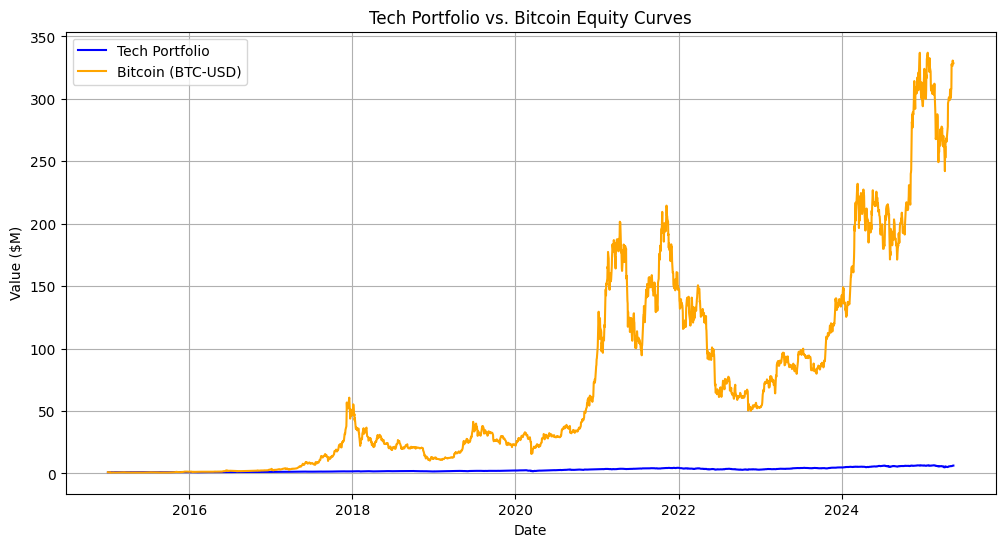

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define tech ETFs and Bitcoin
tech_etfs = ['QQQ', 'XLK', 'VGT', 'IYW', 'IXN']
tickers = tech_etfs + ['BTC-USD']

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = datetime(2015, 1, 1)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure BTC-USD and all tech ETFs are included
if 'BTC-USD' not in tickers:
    raise ValueError("BTC-USD data unavailable for the specified period.")
missing_etfs = [t for t in tech_etfs if t not in tickers]
if missing_etfs:
    raise ValueError(f"Missing data for ETFs: {missing_etfs}")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Initialize tech portfolio
initial_investment = 1000000  # $1M
tech_value = []
tech_weights_df = pd.DataFrame(index=data.index, columns=tech_etfs)
n_tech = len(tech_etfs)
tech_weight = 1.0 / n_tech  # 20% per ETF

# Rebalance tech portfolio annually
current_date = start_date
tech_holdings = initial_investment
tech_shares = pd.Series(0.0, index=tech_etfs)

while current_date <= data.index[-1]:
    # Set equal weights
    weights = pd.Series(tech_weight, index=tech_etfs)

    # Store weights
    tech_weights_df.loc[current_date] = weights

    # Calculate shares to buy
    prices = data.loc[current_date][tech_etfs]
    allocation = tech_holdings * weights
    tech_shares = allocation / prices

    # Find next rebalance date (end of year)
    next_rebalance = current_date + pd.offsets.YearEnd()
    if next_rebalance > data.index[-1]:
        next_rebalance = data.index[-1]

    # Calculate portfolio value until next rebalance
    date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
    for date in date_range:
        tech_value.append((tech_shares * data.loc[date][tech_etfs]).sum())
        tech_weights_df.loc[date] = tech_weights_df.loc[current_date]

    # Update portfolio holdings
    tech_holdings = tech_value[-1]

    # Move to next trading day after rebalance
    current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

# Create tech portfolio value Series
tech_value = pd.Series(tech_value, index=data.index[:len(tech_value)])

# Calculate Bitcoin performance
btc_value = initial_investment * (data['BTC-USD'] / data['BTC-USD'][start_date])

# Calculate daily returns
tech_daily_returns = tech_value.pct_change().dropna()
btc_daily_returns = btc_value.pct_change().dropna()

# Align returns for correlation
aligned_returns = pd.DataFrame({
    'Tech': tech_daily_returns,
    'BTC': btc_daily_returns
}).dropna()

# Calculate correlations
overall_correlation = aligned_returns['Tech'].corr(aligned_returns['BTC'])
# 30-day correlation (last 30 trading days)
recent_30_days = aligned_returns.tail(30)
correlation_30_day = recent_30_days['Tech'].corr(recent_30_days['BTC']) if len(recent_30_days) >= 30 else np.nan
# 90-day correlation (last 90 trading days)
recent_90_days = aligned_returns.tail(90)
correlation_90_day = recent_90_days['Tech'].corr(recent_90_days['BTC']) if len(recent_90_days) >= 90 else np.nan

# Calculate metrics for tech portfolio
years = (tech_value.index[-1] - tech_value.index[0]).days / 365.25
tech_annualized_return = ((tech_value[-1] / initial_investment) ** (1/years) - 1) * 100
tech_sharpe = (tech_daily_returns.mean() * 252 - 0.02) / (tech_daily_returns.std() * np.sqrt(252))
tech_rolling_max = tech_value.cummax()
tech_drawdown = (tech_value - tech_rolling_max) / tech_rolling_max
tech_max_drawdown = tech_drawdown.min() * 100

# Calculate metrics for Bitcoin
btc_annualized_return = ((btc_value[-1] / initial_investment) ** (1/years) - 1) * 100
btc_sharpe = (btc_daily_returns.mean() * 252 - 0.02) / (btc_daily_returns.std() * np.sqrt(252))
btc_rolling_max = btc_value.cummax()
btc_drawdown = (btc_value - btc_rolling_max) / btc_rolling_max
btc_max_drawdown = btc_drawdown.min() * 100

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
print("\nTech Portfolio Metrics:")
print(f"Annualized Return: {tech_annualized_return:.2f}%")
print(f"Sharpe Ratio: {tech_sharpe:.2f}")
print(f"Max Drawdown: {tech_max_drawdown:.2f}%")
print("\nBitcoin (BTC-USD) Metrics:")
print(f"Annualized Return: {btc_annualized_return:.2f}%")
print(f"Sharpe Ratio: {btc_sharpe:.2f}")
print(f"Max Drawdown: {btc_max_drawdown:.2f}%")
print("\nCorrelation Metrics:")
print(f"Overall Correlation (2015–2025): {overall_correlation:.2f}")
print(f"30-Day Correlation (Recent): {correlation_30_day:.2f}" if not np.isnan(correlation_30_day) else "30-Day Correlation: Insufficient data")
print(f"90-Day Correlation (Recent): {correlation_90_day:.2f}" if not np.isnan(correlation_90_day) else "90-Day Correlation: Insufficient data")

# Plot equity curves
plt.figure(figsize=(12, 6))
plt.plot(tech_value.index, tech_value / initial_investment, label='Tech Portfolio', color='blue')
plt.plot(btc_value.index, btc_value / initial_investment, label='Bitcoin (BTC-USD)', color='orange')
plt.title('Tech Portfolio vs. Bitcoin Equity Curves')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
# plt.savefig('tech_btc_equity_curve.png')
# plt.close()

# Save results to file
results = {
    'Start Date': start_date.strftime('%Y-%m-%d'),
    'Tech Annualized Return (%)': tech_annualized_return,
    'Tech Sharpe Ratio': tech_sharpe,
    'Tech Max Drawdown (%)': tech_max_drawdown,
    'BTC Annualized Return (%)': btc_annualized_return,
    'BTC Sharpe Ratio': btc_sharpe,
    'BTC Max Drawdown (%)': btc_max_drawdown,
    'Overall Correlation (2015–2025)': overall_correlation,
    '30-Day Correlation': correlation_30_day if not np.isnan(correlation_30_day) else 'Insufficient data',
    '90-Day Correlation': correlation_90_day if not np.isnan(correlation_90_day) else 'Insufficient data'
}
pd.Series(results).to_csv('tech_btc_results.csv')

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define tech ETFs and Bitcoin
tech_etfs = ['QQQ', 'XLK', 'VGT', 'IYW', 'IXN']
tickers = tech_etfs + ['BTC-USD']

# Set backtest period
end_date = datetime(2025, 5, 19)
start_date = datetime(2015, 1, 1)

# Fetch unadjusted close prices
data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']

# Drop any tickers with all NaN data
data = data.dropna(axis=1, how='all')
available_tickers = data.columns
if len(available_tickers) < len(tickers):
    print(f"Warning: Dropped tickers with no data: {[t for t in tickers if t not in available_tickers]}")
tickers = available_tickers

# Ensure BTC-USD and all tech ETFs are included
if 'BTC-USD' not in tickers:
    raise ValueError("BTC-USD data unavailable for the specified period.")
missing_etfs = [t for t in tech_etfs if t not in tickers]
if missing_etfs:
    raise ValueError(f"Missing data for ETFs: {missing_etfs}")

# Find first date with data for all tickers
data = data.dropna()
if data.empty:
    raise ValueError("No common data available for all tickers in the specified period.")
start_date = data.index[0]

# Initialize tech portfolio
initial_investment = 1000000  # $1M
tech_value = []
tech_weights_df = pd.DataFrame(index=data.index, columns=tech_etfs)
n_tech = len(tech_etfs)
tech_weight = 1.0 / n_tech  # 20% per ETF

# Rebalance tech portfolio annually
current_date = start_date
tech_holdings = initial_investment
tech_shares = pd.Series(0.0, index=tech_etfs)

while current_date <= data.index[-1]:
    # Set equal weights
    weights = pd.Series(tech_weight, index=tech_etfs)

    # Store weights
    tech_weights_df.loc[current_date] = weights

    # Calculate shares to buy
    prices = data.loc[current_date][tech_etfs]
    allocation = tech_holdings * weights
    tech_shares = allocation / prices

    # Find next rebalance date (end of year)
    next_rebalance = current_date + pd.offsets.YearEnd()
    if next_rebalance > data.index[-1]:
        next_rebalance = data.index[-1]

    # Calculate portfolio value until next rebalance
    date_range = data.index[(data.index >= current_date) & (data.index <= next_rebalance)]
    for date in date_range:
        tech_value.append((tech_shares * data.loc[date][tech_etfs]).sum())
        tech_weights_df.loc[date] = tech_weights_df.loc[current_date]

    # Update portfolio holdings
    tech_holdings = tech_value[-1]

    # Move to next trading day after rebalance
    current_date = data.index[data.index > next_rebalance][0] if data.index[-1] > next_rebalance else data.index[-1] + pd.offsets.Day(1)

# Create tech portfolio value Series
tech_value = pd.Series(tech_value, index=data.index[:len(tech_value)])

# Calculate Bitcoin performance
btc_value = initial_investment * (data['BTC-USD'] / data['BTC-USD'][start_date])

# Calculate daily returns
tech_daily_returns = tech_value.pct_change().dropna()
btc_daily_returns = btc_value.pct_change().dropna()

# Align returns for correlation
aligned_returns = pd.DataFrame({
    'Tech': tech_daily_returns,
    'BTC': btc_daily_returns
}).dropna()

# Calculate lagged correlations
lags = [-30, -10, -5, -1, 0, 1, 5, 10, 30]
lagged_correlations = {'Full Period': {}, '90-Day': {}, '30-Day': {}}

# Full period
for lag in lags:
    if lag >= 0:
        shifted_btc = aligned_returns['BTC'].shift(lag)
        corr = aligned_returns['Tech'].corr(shifted_btc)
    else:
        shifted_tech = aligned_returns['Tech'].shift(-lag)
        corr = shifted_tech.corr(aligned_returns['BTC'])
    lagged_correlations['Full Period'][lag] = corr if not np.isnan(corr) else np.nan

# 90-day period
recent_90_days = aligned_returns.tail(90)
for lag in lags:
    if len(recent_90_days) < abs(lag):
        lagged_correlations['90-Day'][lag] = np.nan
        continue
    if lag >= 0:
        shifted_btc = recent_90_days['BTC'].shift(lag)
        corr = recent_90_days['Tech'].corr(shifted_btc)
    else:
        shifted_tech = recent_90_days['Tech'].shift(-lag)
        corr = shifted_tech.corr(recent_90_days['BTC'])
    lagged_correlations['90-Day'][lag] = corr if not np.isnan(corr) else np.nan

# 30-day period
recent_30_days = aligned_returns.tail(30)
for lag in lags:
    if len(recent_30_days) < abs(lag):
        lagged_correlations['30-Day'][lag] = np.nan
        continue
    if lag >= 0:
        shifted_btc = recent_30_days['BTC'].shift(lag)
        corr = recent_30_days['Tech'].corr(shifted_btc)
    else:
        shifted_tech = recent_30_days['Tech'].shift(-lag)
        corr = shifted_tech.corr(recent_30_days['BTC'])
    lagged_correlations['30-Day'][lag] = corr if not np.isnan(corr) else np.nan

# Calculate metrics for tech portfolio
years = (tech_value.index[-1] - tech_value.index[0]).days / 365.25
tech_annualized_return = ((tech_value.iloc[-1] / initial_investment) ** (1/years) - 1) * 100
tech_sharpe = (tech_daily_returns.mean() * 252 - 0.02) / (tech_daily_returns.std() * np.sqrt(252))
tech_rolling_max = tech_value.cummax()
tech_drawdown = (tech_value - tech_rolling_max) / tech_rolling_max
tech_max_drawdown = tech_drawdown.min() * 100

# Calculate metrics for Bitcoin
btc_annualized_return = ((btc_value.iloc[-1] / initial_investment) ** (1/years) - 1) * 100
btc_sharpe = (btc_daily_returns.mean() * 252 - 0.02) / (btc_daily_returns.std() * np.sqrt(252))
btc_rolling_max = btc_value.cummax()
btc_drawdown = (btc_value - btc_rolling_max) / btc_rolling_max
btc_max_drawdown = btc_drawdown.min() * 100

# Print results
print(f"Start Date: {start_date.strftime('%Y-%m-%d')}")
print("\nTech Portfolio Metrics:")
print(f"Annualized Return: {tech_annualized_return:.2f}%")
print(f"Sharpe Ratio: {tech_sharpe:.2f}")
print(f"Max Drawdown: {tech_max_drawdown:.2f}%")
print("\nBitcoin (BTC-USD) Metrics:")
print(f"Annualized Return: {btc_annualized_return:.2f}%")
print(f"Sharpe Ratio: {btc_sharpe:.2f}")
print(f"Max Drawdown: {btc_max_drawdown:.2f}%")
print("\nLagged Correlation Metrics (Tech vs. BTC):")
for period in lagged_correlations:
    print(f"\n{period}:")
    for lag in lags:
        corr = lagged_correlations[period][lag]
        if not np.isnan(corr):
            print(f"Lag {lag} days: {corr:.2f}")
        else:
            print(f"Lag {lag} days: Insufficient data")

# Plot equity curves
plt.figure(figsize=(12, 6))
plt.plot(tech_value.index, tech_value / initial_investment, label='Tech Portfolio', color='blue')
plt.plot(btc_value.index, btc_value / initial_investment, label='Bitcoin (BTC-USD)', color='orange')
plt.title('Tech Portfolio vs. Bitcoin Equity Curves')
plt.xlabel('Date')
plt.ylabel('Value ($M)')
plt.legend()
plt.grid(True)
plt.savefig('tech_btc_equity_curve.png')
plt.close()

# Plot lagged correlations
plt.figure(figsize=(12, 6))
for period in lagged_correlations:
    valid_lags = [lag for lag in lags if not np.isnan(lagged_correlations[period][lag])]
    valid_corrs = [lagged_correlations[period][lag] for lag in valid_lags]
    plt.plot(valid_lags, valid_corrs, marker='o', label=period)
plt.axhline(0, color='black', linestyle='--', alpha=0.3)
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.title('Lagged Correlation: Tech Portfolio vs. Bitcoin')
plt.xlabel('Lag (Days, Negative = BTC Leads, Positive = Tech Leads)')
plt.ylabel('Correlation Coefficient')
plt.legend()
plt.grid(True)
plt.savefig('lagged_correlation_plot.png')
plt.close()

# Save results to file
results = {
    'Start Date': start_date.strftime('%Y-%m-%d'),
    'Tech Annualized Return (%)': tech_annualized_return,
    'Tech Sharpe Ratio': tech_sharpe,
    'Tech Max Drawdown (%)': tech_max_drawdown,
    'BTC Annualized Return (%)': btc_annualized_return,
    'BTC Sharpe Ratio': btc_sharpe,
    'BTC Max Drawdown (%)': btc_max_drawdown
}
for period in lagged_correlations:
    for lag in lags:
        corr = lagged_correlations[period][lag]
        results[f"{period} Correlation Lag {lag}"] = corr if not np.isnan(corr) else 'Insufficient data'
pd.Series(results).to_csv('tech_btc_lagged_results.csv')

Start Date: 2015-01-02

Tech Portfolio Metrics:
Annualized Return: 19.41%
Sharpe Ratio: 0.79
Max Drawdown: -36.27%

Bitcoin (BTC-USD) Metrics:
Annualized Return: 74.87%
Sharpe Ratio: 1.14
Max Drawdown: -83.04%

Lagged Correlation Metrics (Tech vs. BTC):

Full Period:
Lag -30 days: 0.02
Lag -10 days: -0.02
Lag -5 days: 0.03
Lag -1 days: -0.02
Lag 0 days: 0.23
Lag 1 days: -0.03
Lag 5 days: 0.00
Lag 10 days: -0.03
Lag 30 days: -0.01

90-Day:
Lag -30 days: 0.00
Lag -10 days: -0.06
Lag -5 days: 0.08
Lag -1 days: -0.12
Lag 0 days: 0.44
Lag 1 days: -0.00
Lag 5 days: -0.18
Lag 10 days: -0.05
Lag 30 days: -0.15

30-Day:
Lag -30 days: Insufficient data
Lag -10 days: -0.03
Lag -5 days: -0.07
Lag -1 days: -0.27
Lag 0 days: 0.51
Lag 1 days: -0.26
Lag 5 days: -0.40
Lag 10 days: -0.23
Lag 30 days: Insufficient data
